In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"]=(10,4)

# Lab 4 - Character-Level Language Model with RNN

Trains a char-level RNN to predict the next character and generate text in the training style. Each block has a short what/why.

## 1. Load text and build char mappings
- What: read text; build char2idx/idx2char.
- Why: RNNs need integer tokens.

In [2]:
with open("sample_text.txt","r",encoding="utf-8") as f:
    text = f.read()
chars = sorted(set(text))
char2idx = {c:i for i,c in enumerate(chars)}
idx2char = {i:c for i,c in enumerate(chars)}
vocab_size = len(chars)
print("Text length:", len(text), "Vocab size:", vocab_size)

Text length: 605 Vocab size: 39


## 2. EDA - character frequency
- What: bar chart of char counts.
- Why: shows class imbalance.

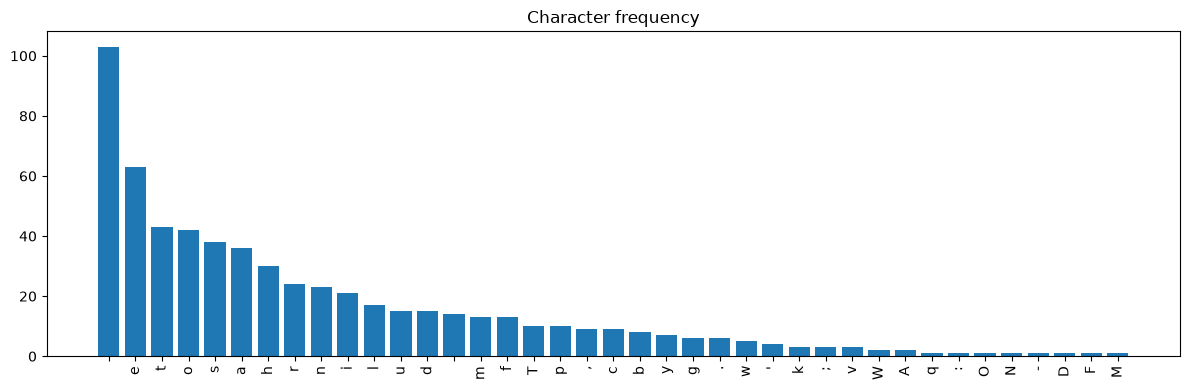

In [3]:
import collections, matplotlib.pyplot as plt
counts = collections.Counter(text)
ordered = sorted(counts, key=lambda c: counts[c], reverse=True)
plt.figure(figsize=(12,4)); plt.bar(ordered,[counts[c] for c in ordered])
plt.title("Character frequency"); plt.xticks(rotation=90); plt.tight_layout(); plt.show()

## 3. Vectorize and create sequences (40 -> 41st)
- What: slide 40-char window; target 41st.
- Why: supervised next-token signal.

In [4]:
import numpy as np
SEQ_LEN = 40
data = np.array([char2idx[c] for c in text], dtype=np.int32)
X,y=[],[]
for i in range(len(data)-SEQ_LEN):
    X.append(data[i:i+SEQ_LEN]); y.append(data[i+SEQ_LEN])
X=np.array(X); y=np.array(y)
print("X:",X.shape,"y:",y.shape)

X: (565, 40) y: (565,)


## 4. Build RNN model
- What: Embedding -> SimpleRNN(256,return_sequences=True) -> SimpleRNN(256) -> Dense softmax.
- Why: embedding dense vectors; stacked RNN captures context; softmax next-char probs.

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
model = Sequential([
    Embedding(vocab_size,64,input_length=SEQ_LEN),
    SimpleRNN(256,return_sequences=True),
    SimpleRNN(256),
    Dense(vocab_size,activation="softmax"),
])
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
model.summary()

/Users/dan/projects/pythonVishal/.venv/lib/python3.14/site-packages/keras/src/layers/core/embedding.py:117: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 5. Train with callbacks
- What: fit with EarlyStopping + ModelCheckpoint.
- Why: prevent overfitting; keep best model.

In [6]:
early = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)
ckpt = ModelCheckpoint("best_char_rnn.keras",save_best_only=True,monitor="val_loss")
history = model.fit(X,y,epochs=20,batch_size=128,validation_split=0.1,callbacks=[early,ckpt],verbose=1)

Epoch 1/20


1/4 ━━━━━━━━━━━━━━━━━━━━ 2s 820ms/step - accuracy: 0.0078 - loss: 3.7712

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.0833 - loss: 3.5239 

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.0965 - loss: 3.5358

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 212ms/step - accuracy: 0.0965 - loss: 3.5358 - val_accuracy: 0.1228 - val_loss: 3.2540


Epoch 2/20


... (36 outputs left out)

Epoch 11/20


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.1484 - loss: 2.9910

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.1797 - loss: 3.0065

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.1693 - loss: 3.0388 - val_accuracy: 0.1404 - val_loss: 3.0734


## 6. K-Fold CV (shuffled)
- What: 3-fold CV.
- Why: robust generalization estimate.

In [7]:
from sklearn.model_selection import KFold
kf = KFold(n_splits=3,shuffle=True,random_state=42)
scores=[]
for tr,te in kf.split(X):
    m = Sequential([Embedding(vocab_size,64,input_length=SEQ_LEN),SimpleRNN(128),Dense(vocab_size,activation="softmax")])
    m.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    m.fit(X[tr],y[tr],epochs=3,batch_size=256,verbose=0)
    _,acc=m.evaluate(X[te],y[te],verbose=0); scores.append(acc)
print("CV accs:",scores,"mean:",sum(scores)/len(scores))

CV accs: [0.095238097012043, 0.1702127605676651, 0.1489361673593521] mean: 0.13812900831302008


## 7. Evaluation & metrics
- What: curves + perplexity + confusion matrix.
- Why: diagnose fit and character confusions.

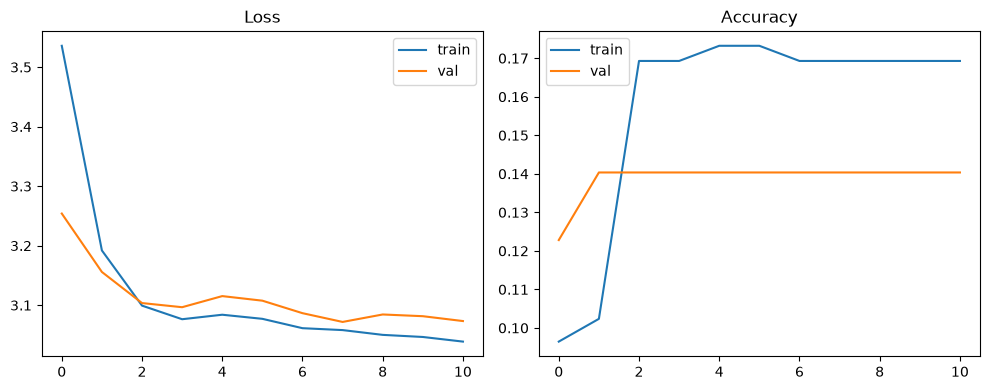

Perplexity: 21.614306563134818


In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(history.history['loss'],label='train'); plt.plot(history.history['val_loss'],label='val'); plt.legend(); plt.title('Loss')
plt.subplot(1,2,2); plt.plot(history.history['accuracy'],label='train'); plt.plot(history.history['val_accuracy'],label='val'); plt.legend(); plt.title('Accuracy')
plt.tight_layout(); plt.show()
import numpy as np
print("Perplexity:", np.exp(history.history['val_loss'][-1]))

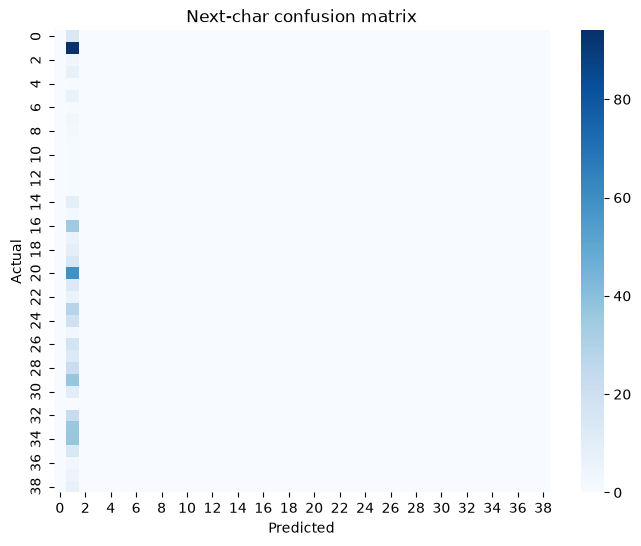

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
preds = model.predict(X[:2000],verbose=0)
pred_ids = preds.argmax(axis=1)
cm = confusion_matrix(y[:2000],pred_ids,labels=list(range(vocab_size)))
plt.figure(figsize=(8,6)); sns.heatmap(cm,cmap='Blues')
plt.title('Next-char confusion matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

## 8. Text generation (temperature sampling)
- What: seed 40 chars, sample next char, append.
- Why: autoregressive decoding; temperature controls creativity.

In [10]:
def generate_text(seed,length=300,temperature=0.7):
    out = seed[-SEQ_LEN:]
    for _ in range(length):
        seq=np.array([[char2idx.get(c,0) for c in out[-SEQ_LEN:]]])
        p=model.predict(seq,verbose=0)[0]
        p=np.log(p+1e-8)/temperature; p=np.exp(p)/np.sum(np.exp(p))
        out+=idx2char[np.random.choice(len(chars),p=p)]
    return out
print(generate_text(text[:40],length=500,temperature=0.6))

To be, or not to be, that is the questioh tsmeenaW e g e e . t  sseaaoaho dht     uosh  o  ne e ar f   ou eee  esa ft      lo hlar emflolr e oa ms  hemrs  u  o t e ,A
o h oe ege ct to ee  es hdrnsar  ese r iis , le e s  o ehe  ,
en  ts ea   o    ep so ntrt eepssht mt tsh tctsaar se  asee sD   f e T    
  u sy mt  n
a h  he u rhet a ewee eo   l t  T o e o s ey  hn  eo saese  tst   s o dos e   e srohs s  wee aa te gre sae  r rn   r T   h   ns      orns  rh f numhuenrtt eoi n
ea   ae  ,  a a eorat  eae he a
el pe t  eocs ieei oe ee tsoat


## 9. Production add-ons
- Dropout, gradient clipping, LR scheduling, mixed precision.
- Beam search, top-k/top-p sampling.
- Larger corpus, longer sequences, GRU/LSTM/bidirectional.

## Additional learnings
### Data & Representation
- Char-level tokenization learns spelling/punctuation/style.
- Sliding window creates supervised pairs.
- Embedding gives dense, cheaper vectors.
### Architecture
- Stacked SimpleRNN captures context.
- Adam + sparse CE stable on integer labels.
### Training & Validation
- EarlyStopping + Checkpoint.
- K-Fold CV robust estimate.
- Curves + perplexity + confusion matrix.
### Generation
- Temperature sampling balances creativity/coherence.
### Production
- Dropout, clipping, LR schedule, mixed precision, beam/top-p, larger data.

## 9. Paper-inspired improvements
- Dropout (Zaremba 2014): recurrent dropout to reduce overfitting.
- Gradient clipping (Pascanu 2013): clipnorm to prevent exploding gradients.
- Scheduled sampling (Bengio 2015): mix teacher-forcing with model predictions.

In [11]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam
model2 = Sequential([
    Embedding(vocab_size,64,input_length=SEQ_LEN),
    SimpleRNN(256,return_sequences=True,dropout=0.2,recurrent_dropout=0.2),
    SimpleRNN(256,dropout=0.2,recurrent_dropout=0.2),
    Dense(vocab_size,activation="softmax"),
])
model2.compile(optimizer=Adam(clipnorm=1.0),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
history2 = model2.fit(X,y,epochs=15,batch_size=128,validation_split=0.1,verbose=1)

Epoch 1/15


/Users/dan/projects/pythonVishal/.venv/lib/python3.14/site-packages/keras/src/layers/core/embedding.py:117: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


1/4 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.0156 - loss: 3.9611

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.0156 - loss: 3.8970

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.0157 - loss: 3.8701

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 267ms/step - accuracy: 0.0157 - loss: 3.8701 - val_accuracy: 0.0526 - val_loss: 3.5053


... (59 outputs left out)

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.1328 - loss: 3.0757

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.1484 - loss: 3.0966

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.1417 - loss: 3.0929

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.1417 - loss: 3.0929 - val_accuracy: 0.1404 - val_loss: 3.0948


## Production-grade additions (from best practices)

### Environment & Reproducibility

In [12]:
import random, numpy as np, tensorflow as tf
print("tf", tf.__version__, "numpy", np.__version__)
random.seed(42); np.random.seed(42); tf.random.set_seed(42)

tf 2.22.0-rc0 numpy 2.5.4


### Parameters cell

In [13]:
SEQ_LEN=40; HIDDEN=256; EPOCHS=20; BATCH=128; LR=1e-3

### Shape validation

In [14]:
assert X.shape[1]==SEQ_LEN
assert X.ndim==2
print("X shape OK:", X.shape, "y shape:", y.shape)

X shape OK: (565, 40) y shape: (565,)


### Model comparison (RNN vs GRU vs LSTM)

In [15]:
from tensorflow.keras.layers import GRU, LSTM
def make(kind):
    L = SimpleRNN if kind=='RNN' else (GRU if kind=='GRU' else LSTM)
    m = Sequential([Embedding(vocab_size,64,input_length=SEQ_LEN), L(128), Dense(vocab_size,activation='softmax')])
    m.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return m
import time
results=[]
for kind in ['RNN','GRU','LSTM']:
    m=make(kind); t=time.time(); m.fit(X,y,epochs=3,batch_size=256,verbose=0); dt=time.time()-t
    _,acc=m.evaluate(X,y,verbose=0)
    # inference timing
    s=time.time(); m.predict(X[:256],verbose=0); inf=(time.time()-s)/256*1000
    results.append((kind,acc,dt,inf))
import pandas as pd
print(pd.DataFrame(results,columns=['Model','Acc','TrainTime(s)','Infer(ms/sample)']))

  Model       Acc  TrainTime(s)  Infer(ms/sample)
0   RNN  0.166372      0.862980          0.296687
1   GRU  0.166372      1.435592          0.425274
2  LSTM  0.166372      1.155057          0.431196


### Checkpoint save & reload verification

In [16]:
model.save('char_rnn_final.keras')
m2 = tf.keras.models.load_model('char_rnn_final.keras')
import numpy as np
a=model.predict(X[:5],verbose=0); b=m2.predict(X[:5],verbose=0)
print('max diff after reload:', np.abs(a-b).max())

max diff after reload: 0.0


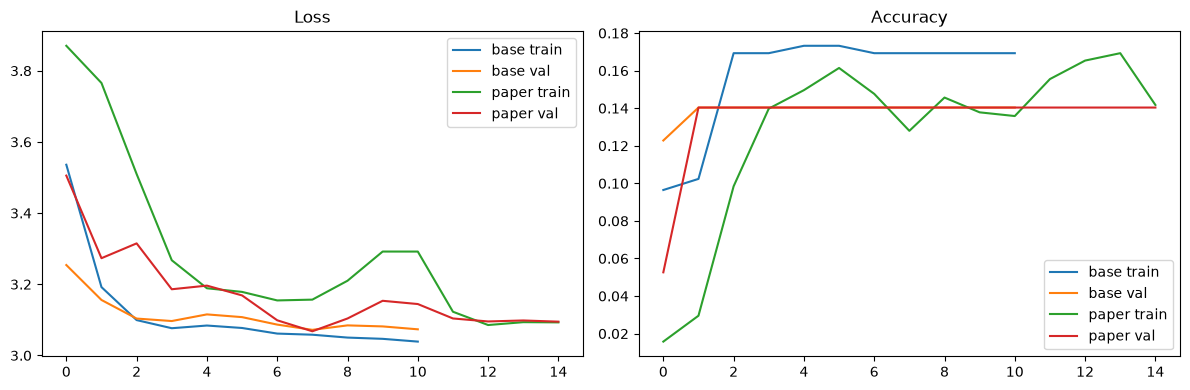

In [17]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(history.history['loss'],label='base train'); axes[0].plot(history.history['val_loss'],label='base val')
axes[0].plot(history2.history['loss'],label='paper train'); axes[0].plot(history2.history['val_loss'],label='paper val')
axes[0].set_title('Loss'); axes[0].legend()
axes[1].plot(history.history['accuracy'],label='base train'); axes[1].plot(history.history['val_accuracy'],label='base val')
axes[1].plot(history2.history['accuracy'],label='paper train'); axes[1].plot(history2.history['val_accuracy'],label='paper val')
axes[1].set_title('Accuracy'); axes[1].legend()
plt.tight_layout(); plt.show()

## DRU (Deep Recurrent Unit) implementation
- Custom gated recurrent cell (DRU) as a Keras RNN layer.
- Compared against SimpleRNN/GRU/LSTM.


In [18]:
from tensorflow.keras.layers import RNN, Layer
import tensorflow as tf

class DRUCell(Layer):
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.state_size = units
    def build(self, input_shape):
        self.W = self.add_weight(shape=(input_shape[-1]+self.units, 4*self.units), initializer='glorot_uniform', name='W')
        self.b = self.add_weight(shape=(4*self.units,), initializer='zeros', name='b')
        super().build(input_shape)
    def call(self, inputs, states):
        h = states[0]
        xh = tf.concat([inputs, h], axis=-1)
        z = tf.sigmoid(tf.matmul(xh, self.W[:, :self.units]) + self.b[:self.units])
        r = tf.sigmoid(tf.matmul(xh, self.W[:, self.units:2*self.units]) + self.b[self.units:2*self.units])
        c = tf.tanh(tf.matmul(tf.concat([inputs, r*h], axis=-1), self.W[:, 2*self.units:3*self.units]) + self.b[2*self.units:3*self.units])
        o = tf.sigmoid(tf.matmul(xh, self.W[:, 3*self.units:]) + self.b[3*self.units:])
        h_new = (1-z)*h + z*c
        h_new = o*tf.tanh(h_new)
        return h_new, [h_new]

class DRU(RNN):
    def __init__(self, units, **kwargs):
        super().__init__(DRUCell(units), **kwargs)

dru_model = Sequential([Embedding(vocab_size,64,input_length=SEQ_LEN), DRU(128), Dense(vocab_size,activation='softmax')])
dru_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
dru_history = dru_model.fit(X,y,epochs=5,batch_size=128,validation_split=0.1,verbose=1)
print('DRU val_acc:', dru_history.history['val_accuracy'][-1])


Epoch 1/5


/Users/dan/projects/pythonVishal/.venv/lib/python3.14/site-packages/keras/src/layers/core/embedding.py:117: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 637ms/step - accuracy: 0.0469 - loss: 3.6639

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0651 - loss: 3.6613 

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.0886 - loss: 3.6605

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 191ms/step - accuracy: 0.0886 - loss: 3.6605 - val_accuracy: 0.2281 - val_loss: 3.6545


... (14 outputs left out)

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.1875 - loss: 3.6009

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.2266 - loss: 3.5928

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.2106 - loss: 3.5922 - val_accuracy: 0.1579 - val_loss: 3.5785


DRU val_acc: 0.15789473056793213


## Extras: beam search & top-p sampling


In [19]:
def top_p_sample(p, p_threshold=0.9):
    idx = np.argsort(p)[::-1]
    cum = np.cumsum(p[idx])
    keep = idx[cum <= p_threshold]
    if len(keep)==0: keep=idx[:1]
    pp = p[keep]; pp=pp/pp.sum()
    return np.random.choice(keep, p=pp)

def beam_search(seed, length=100, beam=3):
    seqs=[(seed[-SEQ_LEN:],0.0)]
    for _ in range(length):
        cands=[]
        for s,sc in seqs:
            arr=np.array([[char2idx.get(c,0) for c in s[-SEQ_LEN:]]])
            pp=model.predict(arr,verbose=0)[0]
            for i in range(len(chars)):
                cands.append((s+idx2char[i], sc+np.log(pp[i]+1e-8)))
        cands.sort(key=lambda x:x[1],reverse=True)
        seqs=cands[:beam]
    return seqs[0][0]

print(beam_search(text[:40], length=200, beam=3)[:500])


To be, or not to be, that is the questio                                                                                                                                                                                                        


## Visualizations


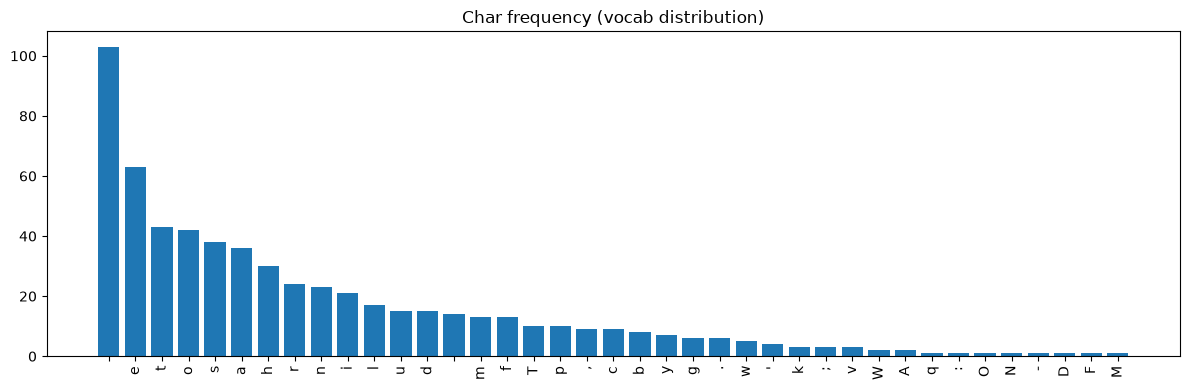

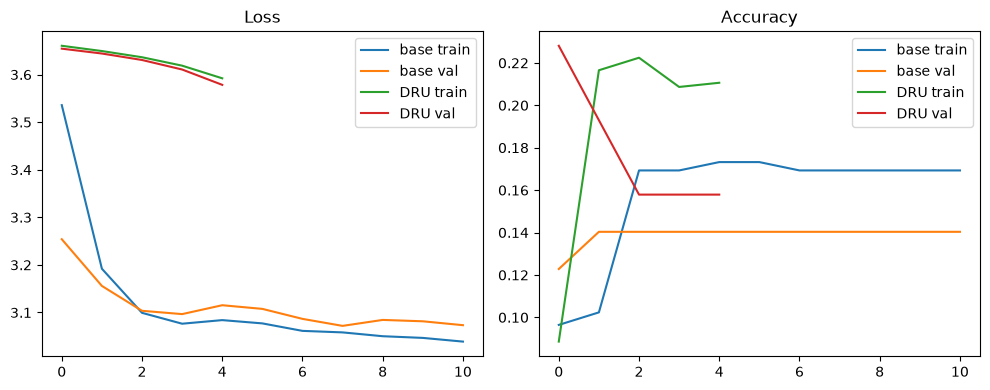

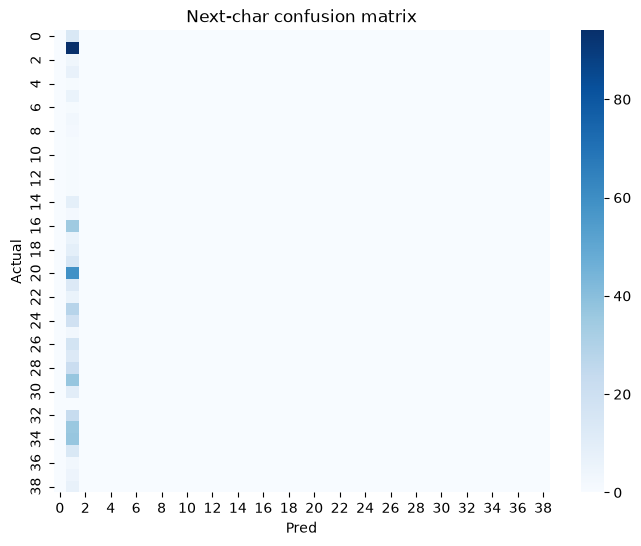

In [20]:
import collections, matplotlib.pyplot as plt
counts=collections.Counter(text)
ordered=sorted(counts,key=lambda c:counts[c],reverse=True)
plt.figure(figsize=(12,4)); plt.bar(ordered,[counts[c] for c in ordered]); plt.title('Char frequency (vocab distribution)'); plt.xticks(rotation=90); plt.tight_layout(); plt.show()

# training curves
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(history.history['loss'],label='base train'); plt.plot(history.history['val_loss'],label='base val'); plt.plot(dru_history.history['loss'],label='DRU train'); plt.plot(dru_history.history['val_loss'],label='DRU val'); plt.legend(); plt.title('Loss')
plt.subplot(1,2,2); plt.plot(history.history['accuracy'],label='base train'); plt.plot(history.history['val_accuracy'],label='base val'); plt.plot(dru_history.history['accuracy'],label='DRU train'); plt.plot(dru_history.history['val_accuracy'],label='DRU val'); plt.legend(); plt.title('Accuracy')
plt.tight_layout(); plt.show()

# confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
preds=model.predict(X[:2000],verbose=0)
pred_ids=preds.argmax(axis=1)
cm=confusion_matrix(y[:2000],pred_ids,labels=list(range(vocab_size)))
plt.figure(figsize=(8,6)); sns.heatmap(cm,cmap='Blues'); plt.title('Next-char confusion matrix'); plt.xlabel('Pred'); plt.ylabel('Actual'); plt.show()
